# STRF → dSTRF → tuning subspace
A small method check before training the Wingert et al. (2026) pilot.

- **STRF:** one fixed linear spectrotemporal filter.
- **dSTRF:** the gradient of one output with respect to its recent input; it can change with context.
- **Subspace:** principal directions across many dSTRFs.

We first check a known linear filter, then probe an official pretrained NEMS CNN.
The CNN is a separate NEMS demo model, **not** a checkpoint from the paper's CLT027c site.
This notebook does not train a model or reproduce the paper's neural prediction scores.

Sources: [paper](https://www.nature.com/articles/s41593-026-02216-0),
[paper data and demo](https://zenodo.org/records/18331549),
[NEMS](https://github.com/LBHB/NEMS).


In [1]:
import os
import sys
from pathlib import Path

os.environ.update(CUDA_VISIBLE_DEVICES="-1", TF_CPP_MIN_LOG_LEVEL="3",
                  TF_NUM_INTRAOP_THREADS="1", TF_NUM_INTEROP_THREADS="1",
                  MPLCONFIGDIR="/tmp/speech-mpl", XDG_CACHE_HOME="/tmp/speech-cache")
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "03_src/strf.py").exists())
sys.path.insert(0, str(root / "03_src"))
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from strf import load_site, tensorflow_model, local_filters, tuning_pca
from nems import Model
from nems.layers import FiniteImpulseResponse
from nems.tools.json import load_model
print(sys.executable)


/clusterfs/bebb/users/tonychae01/envs/env-speech/bin/python


## 1. One real recording
CLT027c has 32 cochleagram channels (200–20,000 Hz), 100 time bins/s, and 20 neurons.
Unique sequences form the training set; the repeated sequence forms the test set.
Its repeats are averaged into a PSTH. Normalization uses training statistics only.
Keep trials separate to avoid artificial stimulus transitions.


Train: (10, 2200, 32) (10, 2200, 20)
Test:  (1, 2200, 32) (1, 2200, 20)


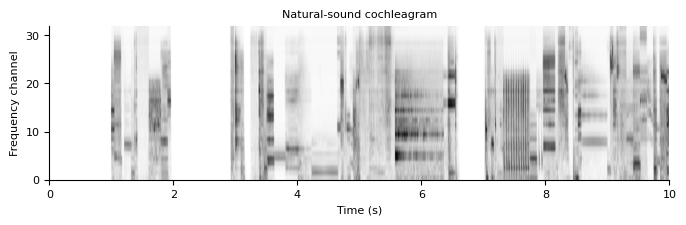

In [2]:
x_train, y_train, x_test, y_test, cellids, scales = load_site()
print("Train:", x_train.shape, y_train.shape)
print("Test: ", x_test.shape, y_test.shape)
# Use one training sequence for the method check; leave test responses untouched.
stimulus = x_train[0]
fig, ax = plt.subplots(figsize=(8, 2))
ax.imshow(stimulus[:1000].T, origin="lower", aspect="auto", cmap="gray_r",
          extent=[0, 10, 0, 32])
ax.set(xlabel="Time (s)", ylabel="Frequency channel", title="Natural-sound cochleagram")
plt.show()


## 2. A fixed STRF
For a linear model, $r(t)=\sum_{f,u}h(f,u)S(f,t-u)$.
Its gradient must equal the same filter at every context.
Here we set a known filter directly; this is an analytic check, not a fitted neural STRF.
Arrays and plots below run from the oldest sample (−240 ms) to the present (0 ms).


In [3]:
history = 25
h = np.zeros((history, 32))  # lag × frequency; lag 0 is the present
h[5, 10] = 1.0
h[10, 20] = -0.5
linear = Model(layers=[FiniteImpulseResponse(shape=h.shape)])
linear.layers[0].set_parameter_values(coefficients=h)
linear_network = tensorflow_model(linear)
times = np.linspace(150, len(stimulus) - 150, 64, dtype=int)
linear_d = local_filters(linear_network, stimulus, times)
linear_error = float(np.max(np.abs(linear_d - h[::-1].T)))
assert linear_error < 1e-6
print("Max gradient error:", linear_error)


Max gradient error: 0.0


## 3. Probe one CNN output
We use output 0 (identified below), chosen before looking at gradients.
This model was trained on other recordings: **do not compare its outputs with CLT027c neurons**.
Only the stimulus is reused here to check gradient extraction.

`local_filters` uses NEMS layer conversions and a scalar TensorFlow gradient.
It avoids a vectorized-Jacobian error encountered in NEMS with this TensorFlow version.
We verify the TensorFlow and NEMS forward passes agree.


In [4]:
cnn = load_model(str(root / "06_external/wingert2026/nems_demo_cnn32.json"))
network = tensorflow_model(cnn)
unit = 0
print("Demo-model output:", cnn.meta["cellids"][unit])
d = local_filters(network, stimulus, times, unit=unit)
assert d.shape == (64, 32, history) and np.isfinite(d).all()
print("dSTRF shape (context, frequency, lag):", d.shape)


Demo-model output: ARM029a-04-1


dSTRF shape (context, frequency, lag): (64, 32, 25)


## 4. Check the derivative
A central finite difference should match the gradient for a small input perturbation.
We check the largest gradient coordinate and several random directions, then compare
forward predictions across contexts. These are numerical checks, not prediction scores.


In [5]:
sample, frequency, lag = np.unravel_index(np.abs(d).argmax(), d.shape)
t = times[sample]
window = stimulus[t-history+1:t+1].astype("float32")
rng = np.random.default_rng(0)
directions = rng.normal(size=(4, history, 32)).astype("float32")
directions /= np.linalg.norm(directions, axis=(1, 2), keepdims=True)
directions = np.concatenate([np.eye(1, history * 32, lag * 32 + frequency)
                              .reshape(1, history, 32), directions]).astype("float32")
epsilon = 1e-3
finite = np.array([(network((window + epsilon*v)[None])[0, -1, unit] -
                    network((window - epsilon*v)[None])[0, -1, unit]).numpy()
                   / (2 * epsilon) for v in directions])
analytic = np.einsum("tf,ntf->n", d[sample].T, directions)
np.testing.assert_allclose(finite, analytic, rtol=0.03, atol=2e-4)
forward_errors = []
for t in times[::8]:
    w = stimulus[t-history+1:t+1].astype("float32")
    forward_errors.append(abs(float(network(w[None])[0, -1, unit]) - cnn.predict(w)[-1, unit]))
forward_error = float(max(forward_errors))
assert forward_error < 1e-5
print("Max finite-difference error:", float(np.max(np.abs(finite - analytic))))
print("Max forward-pass error:", forward_error)


Max finite-difference error: 1.4696472185327103e-06
Max forward-pass error: 1.734723475976807e-17


## 5. Compare contexts
Red and blue indicate opposite signs of local sensitivity. Color limits are shared
across the CNN panels. Zero gradients may occur when an output is locally inactive.
The mean CNN gradient is a descriptive average, not a fitted STRF baseline.


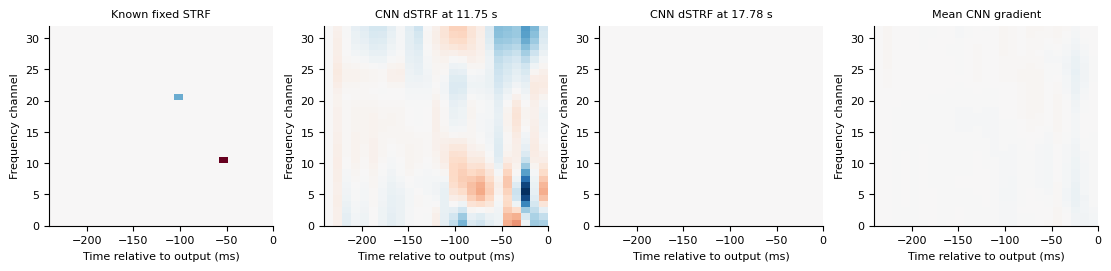

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.6), constrained_layout=True)
axes[0].imshow(h[::-1].T, origin="lower", aspect="auto", cmap="RdBu_r",
               vmin=-1, vmax=1, extent=[-240, 0, 0, 32])
axes[0].set_title("Known fixed STRF")
selected = [sample, (sample + 20) % len(times)]
limit = max(np.abs(d[selected]).max(), 1e-9)
for ax, i in zip(axes[1:3], selected):
    ax.imshow(d[i], origin="lower", aspect="auto", cmap="RdBu_r",
              vmin=-limit, vmax=limit, extent=[-240, 0, 0, 32])
    ax.set_title(f"CNN dSTRF at {times[i]/100:.2f} s")
axes[3].imshow(d.mean(axis=0), origin="lower", aspect="auto", cmap="RdBu_r",
               vmin=-limit, vmax=limit, extent=[-240, 0, 0, 32])
axes[3].set_title("Mean CNN gradient")
for ax in axes:
    ax.set(xlabel="Time relative to output (ms)", ylabel="Frequency channel")
out = root / "05_results/wingert_smoke"
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "strf_dstrf.png", dpi=150)
plt.show()


## 6. PCA across contexts
Flatten each dSTRF into 800 features and apply centered PCA, as in the authors' demo.
Save the mean filter separately: centered PCs describe deviations around it.
Use the actual explained-variance ratio, not its square root.
With 64 samples, centered PCA has at most 63 nonzero dimensions. This sample is too
small for a stable biological dimensionality estimate or a population-level conclusion.


Components for 95% of sampled gradient variance: 3


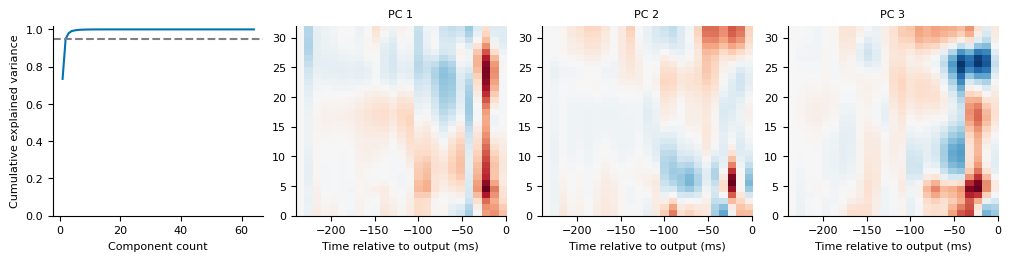

In [7]:
pca, cumulative, k95 = tuning_pca(d)
print("Components for 95% of sampled gradient variance:", k95)
fig, axes = plt.subplots(1, 4, figsize=(10, 2.5), constrained_layout=True)
axes[0].plot(np.arange(1, len(cumulative) + 1), cumulative)
axes[0].axhline(0.95, color="gray", linestyle="--")
axes[0].set(xlabel="Component count", ylabel="Cumulative explained variance", ylim=(0, 1.02))
for i, ax in enumerate(axes[1:]):
    pc = pca.components_[i].reshape(32, history)
    limit = np.abs(pc).max()
    ax.imshow(pc, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-limit, vmax=limit,
              extent=[-240, 0, 0, 32])
    ax.set(title=f"PC {i+1}", xlabel="Time relative to output (ms)")
fig.savefig(out / "pca.png", dpi=150)
plt.show()


In [8]:
import json
summary = {
    "scope": "Method smoke check; not a paper-result reproduction",
    "stimulus_site": "CLT027c", "model": "Official NEMS demo CNN32, batch 322",
    "output_cellid": cnn.meta["cellids"][unit], "contexts": len(times),
    "history_bins": history, "linear_gradient_max_error": linear_error,
    "finite_difference_max_error": float(np.max(np.abs(finite - analytic))),
    "forward_max_error": forward_error, "centered_pca_k95": k95,
    "training_performed": False,
}
(out / "metrics.json").write_text(json.dumps(summary, indent=2))
np.savez(out / "filters.npz", dstrf=d, times=times, mean_filter=d.mean(axis=0),
         components=pca.components_, cumulative=cumulative)
summary


{'scope': 'Method smoke check; not a paper-result reproduction',
 'stimulus_site': 'CLT027c',
 'model': 'Official NEMS demo CNN32, batch 322',
 'output_cellid': 'ARM029a-04-1',
 'contexts': 64,
 'history_bins': 25,
 'linear_gradient_max_error': 0.0,
 'finite_difference_max_error': 1.4696472185327103e-06,
 'forward_max_error': 1.734723475976807e-17,
 'centered_pca_k95': 3,
 'training_performed': False}

## Next: fit a small model to the actual neurons
`pipeline/train_pilot.py` fits an LN baseline and a reduced-width CNN to CLT027c,
then saves held-out correlations, learned STRFs, and one unit's dSTRFs.
It refuses to train on the login node. A first small fit has now completed; inspect
`02_wingert_pilot.ipynb` for its results. See `pipeline/README.md` for the batch command.

**Not done in this notebook:** CNN training, SSRF fitting, jackknife/shrinkage, noise-corrected
prediction scores, shared population subspaces, or HuBERT/wav2vec 2.0 analysis.
The paper model ZIP currently contains directories but no checkpoint files.
